# Oil Price–Inflation Analysis: Data Pipeline

**Purpose:** Replicate the full pipeline that generates `maindataset/Analysis_dataset_2014_2025.csv` from three raw source files.

---

## Source Files

| # | File | Contents |
|---|------|---------|
| 1 | `Crude-Oil-Price-(Indian Basket)-Historical.xlsx` | Monthly crude oil FOB prices (Indian Basket), USD/bbl, in financial-year wide format |
| 2 | `Exchange Rate...xlsx` | Monthly average USD/INR (RBI) |
| 3 | `r45_consumer_price_index.csv` | All-India CPI (2012=100), combined General Index + YoY% |

## Output Columns

| Column | Source | Transformation |
|--------|--------|----------------|
| `date` | All | First day of calendar month |
| `oil_price_usd_bbl` | Oil xlsx | Monthly avg oil price (USD/bbl) |
| `cpi_combined_index` | CPI csv | Combined All-India General Index |
| `cpi_inflation_yoy_pct` | CPI csv | Combined YoY % |
| `usd_inr_monthly_avg` | FX xlsx | Monthly avg USD/INR |
| `oil_change_pct` | Derived | MoM % change in oil price |
| `oil_log_return_pct` | Derived | ln(P_t/P_{t-1}) x 100 |
| `oil_volatility_3m` | Derived | Rolling 3-month std dev of log returns |
| `usd_inr_change_pct` | Derived | MoM % change in USD/INR |

---
## 0. Environment Setup

In [1]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install',
                        'pandas', 'openpyxl', 'numpy', 'matplotlib', '-q'])

0

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings, os

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 20)

OIL_FILE   = 'Crude-Oil-Price-(Indian Basket)-Historical.xlsx'
FX_FILE    = 'Exchange Rate of the Indian Rupee vis-à-vis the SDR, US Dollar, Pound Sterling, Euro and Japanese Yen (Monthly Average and end-Month Rates).xlsx'
CPI_FILE   = 'r45_consumer_price_index.csv'
OUT_DIR    = 'maindataset'
OUT_FILE   = os.path.join(OUT_DIR, 'Analysis_dataset_2014_2025.csv')
START_DATE = '2014-01-01'
END_DATE   = '2025-12-01'

print('Imports OK.')

Imports OK.


---
## 1. Crude Oil Price (Indian Basket)

**Source:** PPAC, Ministry of Petroleum & Natural Gas, GoI  
**Layout:** Wide format — each row = one Indian financial year (Apr-Mar), columns = 12 months + annual avg  
**Key step:** Reshape FY-wide -> calendar-monthly long format (Apr-Dec belong to start_year; Jan-Mar to start_year+1)

In [3]:
# 1a. Inspect raw structure
oil_raw = pd.read_excel(OIL_FILE, sheet_name='Sheet1', header=None)
print(f'Raw shape: {oil_raw.shape}')
oil_raw.head(15)

Raw shape: (42, 15)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Petroleum Planning & Analysis Cell,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Crude Oil FOB Price (Indian Basket),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Table Posted: (02-04-2025),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# 1b. Reload skipping the 10 title/header rows; row 10 contains month-column labels
oil_df = pd.read_excel(OIL_FILE, sheet_name='Sheet1', skiprows=10)
print(f'Shape after skiprows=10: {oil_df.shape}')
print('Columns:', oil_df.columns.tolist())
oil_df.head(5)

Shape after skiprows=10: (31, 15)
Columns: ['Period : Since 2000-01', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14']


,Period : Since 2000-01,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,($/bbl.)
1,Year,1991-04-01 00:00:00,1991-05-01 00:00:00,1991-06-01 00:00:00,1991-07-01 00:00:00,1991-08-01 00:00:00,1991-09-01 00:00:00,1991-10-01 00:00:00,1991-11-01 00:00:00,1991-12-01 00:00:00,1992-01-01 00:00:00,1992-02-01 00:00:00,1992-03-01 00:00:00,Average,Ratio *
2,2000-01,22.51,26.6,28.49,27.26,28.328849,31.34,30.5,30.926622,23.25,24.02,25.92,23.82,26.924167,57:43
3,2001-02,24.82,26.95,26.63,23.99,25.01,24.79,20.05,18.24,18.24,18.92,19.529987,23.31,22.551701,57:43
4,2002-03,25.029406,24.994865,24.051814,25.183222,25.855818,27.495243,26.902101,23.682512,27.110101,29.59255,31.308381,28.825039,26.6,57:43


In [5]:
# 1c. Rename columns and filter to financial-year rows only
month_names = ['Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec','Jan','Feb','Mar']
oil_df.columns = ['fin_year'] + month_names + ['annual_avg', 'composition']

# Keep rows where fin_year looks like 'YYYY-YY' (e.g. '2014-15')
oil_df = oil_df[oil_df['fin_year'].astype(str).str.match(r'^\d{4}-\d{2,4}$')].copy()
oil_df = oil_df[['fin_year'] + month_names].reset_index(drop=True)
print(f'Financial-year rows found: {len(oil_df)}')
oil_df.head(6)

Financial-year rows found: 26


,fin_year,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Jan,Feb,Mar
0,2000-01,22.51,26.6,28.49,27.26,28.328849,31.34,30.5,30.926622,23.25,24.02,25.92,23.82
1,2001-02,24.82,26.95,26.63,23.99,25.01,24.79,20.05,18.24,18.24,18.92,19.529987,23.31
2,2002-03,25.029406,24.994865,24.051814,25.183222,25.855818,27.495243,26.902101,23.682512,27.110101,29.59255,31.308381,28.825039
3,2003-04,24.214592,24.988879,26.425925,27.45845,28.663599,26.265218,28.449944,28.226284,28.966611,29.999534,29.647267,32.210323
4,2004-05,32.365205,36.078851,34.159548,36.353382,40.5172,39.149477,43.375467,38.89887,36.816215,40.962002,42.670599,49.27002
5,2005-06,49.427602,46.995224,52.720745,55.008083,60.048336,59.739214,56.279062,53.143808,55.045629,60.542917,58.95333,60.011574


In [6]:
# 1d. Reshape: wide FY x month -> long calendar month time series
#
# Indian FY 2014-15 maps to:
#   Apr-2014, May-2014, ..., Dec-2014  (start_year = 2014)
#   Jan-2015, Feb-2015, Mar-2015       (start_year + 1 = 2015)

def fy_to_calendar_months(row):
    fy_str = str(row['fin_year'])
    yr = int(fy_str.split('-')[0])
    month_map = [
        ('Apr',4,yr),('May',5,yr),('Jun',6,yr),('Jul',7,yr),
        ('Aug',8,yr),('Sep',9,yr),('Oct',10,yr),('Nov',11,yr),
        ('Dec',12,yr),('Jan',1,yr+1),('Feb',2,yr+1),('Mar',3,yr+1),
    ]
    records = []
    for mname, mnum, y in month_map:
        v = row[mname]
        if pd.notna(v):
            try:
                records.append({'date': pd.Timestamp(year=y, month=mnum, day=1),
                                'oil_price_usd_bbl': float(v)})
            except (ValueError, TypeError):
                pass
    return records

oil_records = []
for _, row in oil_df.iterrows():
    oil_records.extend(fy_to_calendar_months(row))

oil_monthly = (
    pd.DataFrame(oil_records)
    .drop_duplicates(subset='date')
    .sort_values('date')
    .set_index('date')
)

print(f'Oil monthly records: {len(oil_monthly)}')
print(f'Range: {oil_monthly.index.min()} to {oil_monthly.index.max()}')
oil_monthly.head(6)

Oil monthly records: 312
Range: 2000-04-01 00:00:00 to 2026-03-01 00:00:00


,oil_price_usd_bbl
date,
2000-04-01,22.510000
2000-05-01,26.600000
2000-06-01,28.490000
2000-07-01,27.260000
2000-08-01,28.328849
2000-09-01,31.340000


---
## 2. USD/INR Exchange Rate

**Source:** Reserve Bank of India (RBI)  
**Layout:** 13 columns, newest rows first. Columns (0-indexed):  
- 0: blank, 1: date (timestamp), 2: Year/Month label  
- 3-4: SDR (avg, end), **5: USD Average** (what we use), 6: USD End  
- 7-8: GBP, 9-10: JPY (per 100 yen), 11-12: EUR  

Data starts at row 8 (0-indexed) — first 8 rows are title + header.

In [7]:
# 2a. Inspect header area
fx_raw_all = pd.read_excel(FX_FILE, sheet_name=None, header=None)
sheet_name = list(fx_raw_all.keys())[0]
fx_df_raw  = fx_raw_all[sheet_name]
print(f'Sheet: "{sheet_name}"  |  Shape: {fx_df_raw.shape}')
print('Rows 5-8 (header area):')
fx_df_raw.iloc[5:9]

Sheet: "EXCHANGE RATE OF THE INDIAN RUP"  |  Shape: (425, 13)
Rows 5-8 (header area):


,0,1,2,3,4,5,6,7,8,9,10,11,12
5,NaN,NaN,Year/Month,SDR,NaN,US Dollar,NaN,Pound Sterling,NaN,Japanese Yen,NaN,Euro,NaN
6,NaN,NaN,NaN,Average,End-month,Average,End-month,Average,End-month,Average,End-month,Average,End-month
7,NaN,NaN,1,2,3,4,5,6,7,8,9,10,11
8,NaN,2026-09-30 00:00:00,Sep-2026,130.5033,130.513,95.464124,95.9832,128.075629,127.1886,61.015714,61.16,109.916743,108.9368


In [8]:
# 2b. Load data (skiprows=8) and extract USD Average column
fx_df = pd.read_excel(FX_FILE, sheet_name=sheet_name, header=None, skiprows=8)
fx_df.columns = [
    'blank','date_raw','year_month',
    'sdr_avg','sdr_end',
    'usd_avg','usd_end',     # <-- column index 5 = USD Monthly Average
    'gbp_avg','gbp_end',
    'jpy_avg','jpy_end',
    'eur_avg','eur_end'
]

fx_df = fx_df[pd.to_datetime(fx_df['date_raw'], errors='coerce').notna()].copy()
fx_df['date'] = pd.to_datetime(fx_df['date_raw']).dt.to_period('M').dt.to_timestamp()
fx_df = (
    fx_df[['date','usd_avg']]
    .rename(columns={'usd_avg': 'usd_inr_monthly_avg'})
    .dropna(subset=['usd_inr_monthly_avg'])
    .drop_duplicates(subset='date')
    .sort_values('date')
    .set_index('date')
)

print(f'FX records: {len(fx_df)}  |  Range: {fx_df.index.min()} to {fx_df.index.max()}')
fx_df.tail(6)

FX records: 415  |  Range: 1992-03-01 00:00:00 to 2026-09-01 00:00:00


,usd_inr_monthly_avg
date,
2026-04-01,93.550242
2026-05-01,95.597500
2026-06-01,94.969548
2026-07-01,95.820970
2026-08-01,95.474110
2026-09-01,95.464124


---
## 3. Consumer Price Index (CPI)

**Source:** MOSPI, Government of India  |  **Base:** 2012 = 100  
**Layout:** Long format — one row per (month x CPI category). Key columns:

| Column | Contents |
|--------|----------|
| `c1` | Month-Year string (e.g. `DEC-2025`) |
| `c2` | Category — filter for `A) General Index` (headline CPI) |
| `c8` | **Combined (All-India) index level** |
| `c9` | **Combined YoY inflation %** |

In [9]:
# 3a. Load raw CPI file
cpi_raw = pd.read_csv(CPI_FILE, encoding='utf-8', on_bad_lines='skip')
print(f'Raw shape: {cpi_raw.shape}')
print('Columns:', cpi_raw.columns.tolist())
cpi_raw.head(3)

Raw shape: (4377, 13)
Columns: ['src_file', 'tab', 'period', 'row_no', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c7', 'c8', 'c9']


,src_file,tab,period,row_no,c1,c2,c3,c4,c5,c6,c7,c8,c9
0,45--consumer-price-index--cpi-2012-100-all-ind...,CPI - 2012=100 (All India),full-history,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,45--consumer-price-index--cpi-2012-100-all-ind...,CPI - 2012=100 (All India),full-history,2,"CPI - Rural, Urban, Combined (All India)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,45--consumer-price-index--cpi-2012-100-all-ind...,CPI - 2012=100 (All India),full-history,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# 3b. Filter for headline CPI (General Index) and extract combined columns
cpi_gen = cpi_raw[cpi_raw['c2'].str.strip() == 'A) General Index'].copy()
print(f'General Index rows: {len(cpi_gen)}')

# Parse 'DEC-2025' -> Timestamp('2025-12-01')
cpi_gen['date'] = pd.to_datetime(cpi_gen['c1'].str.strip(), format='%b-%Y', errors='coerce')
mask = cpi_gen['date'].isna()
if mask.any():
    cpi_gen.loc[mask, 'date'] = pd.to_datetime(
        cpi_gen.loc[mask, 'c1'].str.strip(), format='%B-%Y', errors='coerce')

cpi_gen = cpi_gen.dropna(subset=['date'])[['date','c8','c9']].copy()
cpi_gen.columns = ['date','cpi_combined_index','cpi_inflation_yoy_pct']
cpi_gen['cpi_combined_index']    = pd.to_numeric(cpi_gen['cpi_combined_index'],    errors='coerce')
cpi_gen['cpi_inflation_yoy_pct'] = pd.to_numeric(cpi_gen['cpi_inflation_yoy_pct'], errors='coerce')
cpi_gen['date'] = cpi_gen['date'].dt.to_period('M').dt.to_timestamp()
cpi_gen = cpi_gen.drop_duplicates(subset='date').sort_values('date').set_index('date')

print(f'CPI records: {len(cpi_gen)}  |  Range: {cpi_gen.index.min()} to {cpi_gen.index.max()}')
cpi_gen.head(6)

General Index rows: 156
CPI records: 156  |  Range: 2013-01-01 00:00:00 to 2025-12-01 00:00:00


,cpi_combined_index,cpi_inflation_yoy_pct
date,,
2013-01-01,104.6,NaN
2013-02-01,105.3,NaN
2013-03-01,105.5,NaN
2013-04-01,106.1,NaN
2013-05-01,106.9,NaN
2013-06-01,109.3,NaN


---
## 4. Merge — Inner Join on Date Index

All three datasets are indexed by the first day of each calendar month.  
Inner join retains only months present in **all three** sources, then slice to Jan 2014 – Dec 2025.

In [11]:
merged = oil_monthly.join(cpi_gen, how='inner').join(fx_df, how='inner')
print(f'Merged (pre-filter): {merged.shape}')
merged = merged.loc[START_DATE:END_DATE].copy()
print(f'After 2014-2025 filter: {merged.shape}')
merged.head()

Merged (pre-filter): (156, 4)
After 2014-2025 filter: (144, 4)


,oil_price_usd_bbl,cpi_combined_index,cpi_inflation_yoy_pct,usd_inr_monthly_avg
date,,,,
2014-01-01,105.294999,113.6,8.60,62.07597
2014-02-01,106.188255,113.6,7.88,62.25401
2014-03-01,105.295288,114.2,8.25,61.01399
2014-04-01,105.555339,115.1,8.48,60.35662
2014-05-01,106.853226,115.8,8.33,59.30502


---
## 5. Derive Computed Columns

| Column | Formula |
|--------|---------|
| `oil_change_pct` | `(P_t - P_{t-1}) / P_{t-1} * 100` |
| `oil_log_return_pct` | `ln(P_t / P_{t-1}) * 100` |
| `oil_volatility_3m` | `rolling(3).std(ddof=1)` of log returns |
| `usd_inr_change_pct` | `(R_t - R_{t-1}) / R_{t-1} * 100` |

In [12]:
merged['oil_change_pct']     = merged['oil_price_usd_bbl'].pct_change() * 100
merged['oil_log_return_pct'] = np.log(merged['oil_price_usd_bbl'] /
                                       merged['oil_price_usd_bbl'].shift(1)) * 100
merged['oil_volatility_3m']  = (merged['oil_log_return_pct']
                                .rolling(window=3, min_periods=3).std(ddof=1))
merged['usd_inr_change_pct'] = merged['usd_inr_monthly_avg'].pct_change() * 100

final_cols = [
    'oil_price_usd_bbl','cpi_combined_index','cpi_inflation_yoy_pct',
    'usd_inr_monthly_avg','oil_change_pct','oil_log_return_pct',
    'oil_volatility_3m','usd_inr_change_pct'
]
final_df = merged[final_cols].copy()
final_df.index.name = 'date'
print('Final shape:', final_df.shape)
final_df.describe().round(4)

Final shape: (144, 8)


,oil_price_usd_bbl,cpi_combined_index,cpi_inflation_yoy_pct,usd_inr_monthly_avg,oil_change_pct,oil_log_return_pct,oil_volatility_3m,usd_inr_change_pct
count,144.0000,144.0000,144.0000,144.0000,143.0000,143.0000,141.0000,143.0000
mean,68.2768,153.3896,4.9072,73.0298,0.2226,-0.3681,7.4298,0.2674
std,19.8693,25.8920,1.6994,8.2644,10.7646,11.0626,7.1444,1.1569
min,19.9017,113.6000,0.2500,59.3050,-40.3404,-51.6515,0.4631,-2.4475
25%,54.6013,131.1000,3.6800,66.1926,-5.6421,-5.8077,3.9632,-0.4056
50%,67.0066,148.8500,5.0050,72.0348,0.8483,0.8448,5.8047,0.2262
75%,80.4357,176.5500,6.0250,82.0536,6.1461,5.9645,8.5337,0.8901
max,116.0114,198.0000,8.6000,90.0913,53.7837,43.0377,54.0088,4.0037


---
## 6. Save Output

In [13]:
os.makedirs(OUT_DIR, exist_ok=True)
final_df.to_csv(OUT_FILE)
print(f'Saved: {OUT_FILE}')
print(f'{len(final_df)} rows x {len(final_df.columns)} columns')

Saved: maindataset/Analysis_dataset_2014_2025.csv
144 rows x 8 columns


---
## 7. Validation — Cross-check Against Original

In [14]:
regen = pd.read_csv(OUT_FILE, parse_dates=['date'], index_col='date')
print('Shape:', regen.shape)
print('NaNs:')
print(regen.isnull().sum())

# Spot-check Jan 2014 oil price (expected ~105.295 USD/bbl)
v = regen.loc['2014-01-01', 'oil_price_usd_bbl']
print(f'\nJan-2014 oil price: {v:.4f} USD/bbl  (expected ~105.295)')
print(f'Match: {abs(v - 105.295) < 0.01}')

Shape: (144, 8)
NaNs:
oil_price_usd_bbl        0
cpi_combined_index       0
cpi_inflation_yoy_pct    0
usd_inr_monthly_avg      0
oil_change_pct           1
oil_log_return_pct       1
oil_volatility_3m        3
usd_inr_change_pct       1
dtype: int64

Jan-2014 oil price: 105.2950 USD/bbl  (expected ~105.295)
Match: True


---
## 8. Exploratory Visualisations

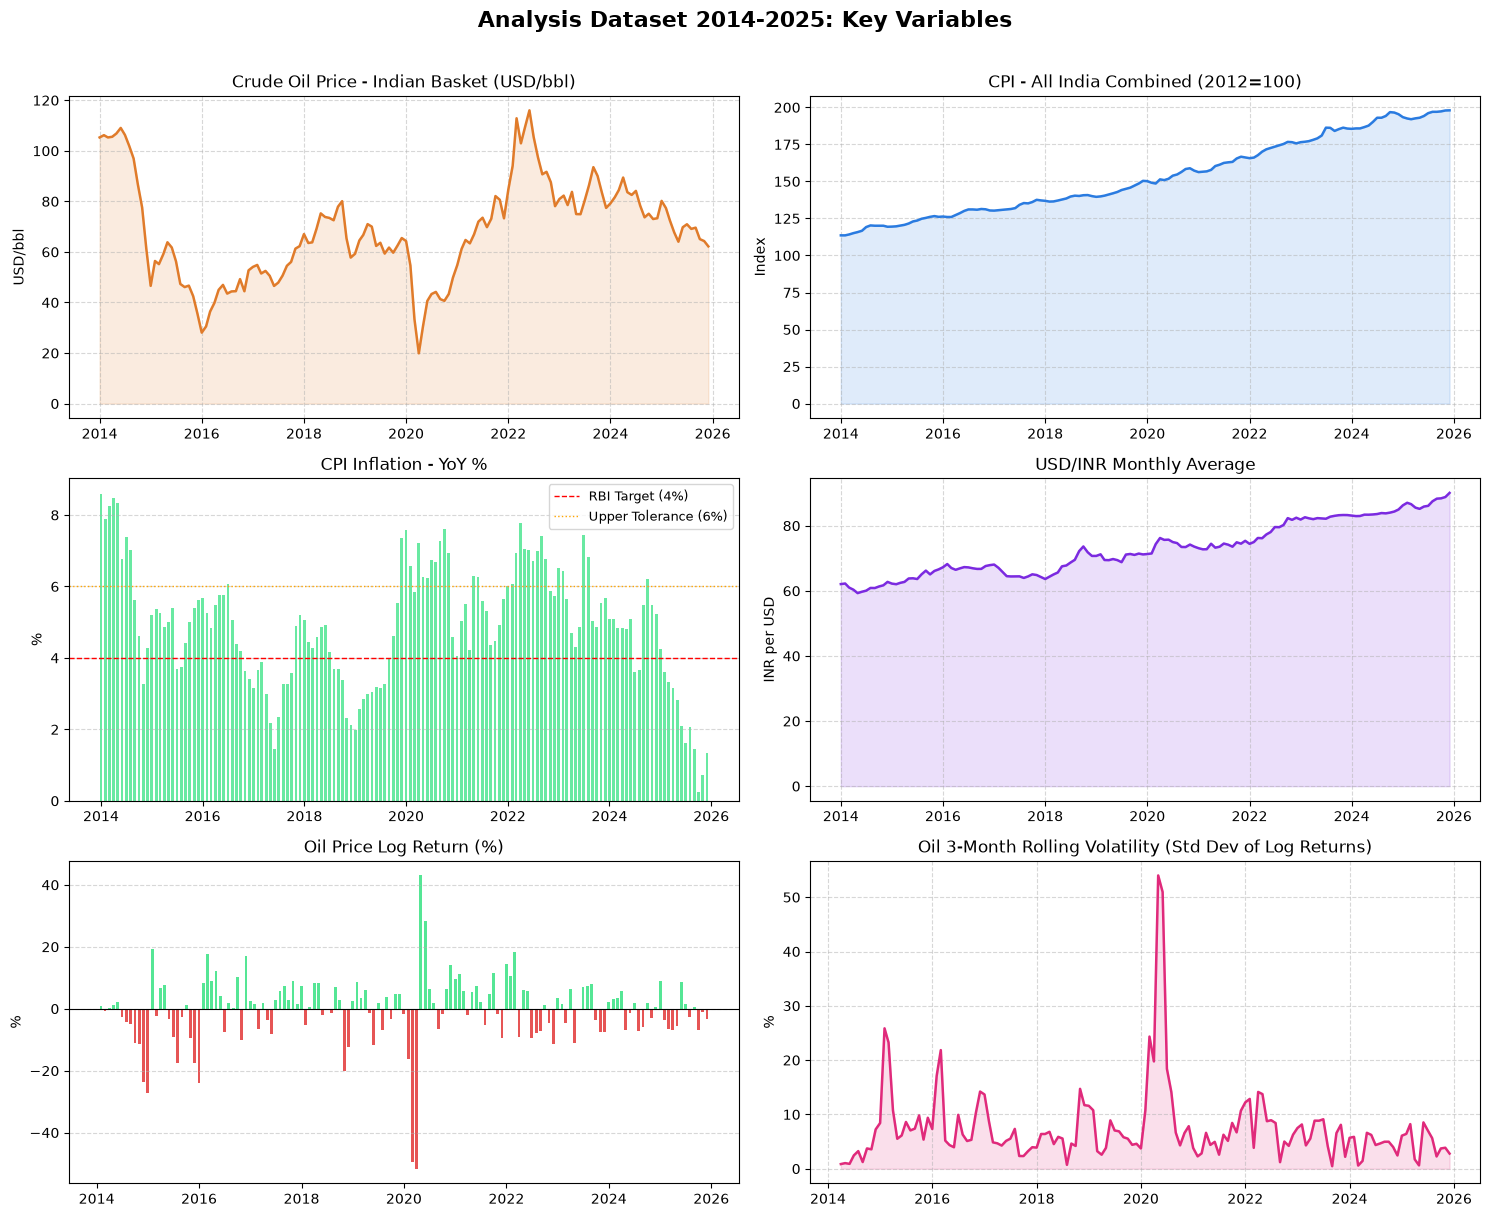

Saved: maindataset/dataset_overview.png


In [15]:
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
fig.suptitle('Analysis Dataset 2014-2025: Key Variables', fontsize=16, fontweight='bold', y=1.01)

p = final_df

ax = axes[0,0]
ax.plot(p.index, p['oil_price_usd_bbl'], color='#e07b2a', lw=1.8)
ax.fill_between(p.index, p['oil_price_usd_bbl'], alpha=0.15, color='#e07b2a')
ax.set_title('Crude Oil Price - Indian Basket (USD/bbl)'); ax.set_ylabel('USD/bbl')
ax.grid(True, ls='--', alpha=0.5)

ax = axes[0,1]
ax.plot(p.index, p['cpi_combined_index'], color='#2a7be0', lw=1.8)
ax.fill_between(p.index, p['cpi_combined_index'], alpha=0.15, color='#2a7be0')
ax.set_title('CPI - All India Combined (2012=100)'); ax.set_ylabel('Index')
ax.grid(True, ls='--', alpha=0.5)

ax = axes[1,0]
ax.bar(p.index, p['cpi_inflation_yoy_pct'], width=20, color='#2ae07b', alpha=0.7)
ax.axhline(4, ls='--', color='red', lw=1, label='RBI Target (4%)')
ax.axhline(6, ls=':', color='orange', lw=1, label='Upper Tolerance (6%)')
ax.set_title('CPI Inflation - YoY %'); ax.set_ylabel('%'); ax.legend(fontsize=9)
ax.grid(True, ls='--', alpha=0.5, axis='y')

ax = axes[1,1]
ax.plot(p.index, p['usd_inr_monthly_avg'], color='#7b2ae0', lw=1.8)
ax.fill_between(p.index, p['usd_inr_monthly_avg'], alpha=0.15, color='#7b2ae0')
ax.set_title('USD/INR Monthly Average'); ax.set_ylabel('INR per USD')
ax.grid(True, ls='--', alpha=0.5)

ax = axes[2,0]
cols = ['#e02a2a' if v < 0 else '#2ae07b' for v in p['oil_log_return_pct'].fillna(0)]
ax.bar(p.index, p['oil_log_return_pct'], width=20, color=cols, alpha=0.8)
ax.axhline(0, color='black', lw=0.8)
ax.set_title('Oil Price Log Return (%)'); ax.set_ylabel('%')
ax.grid(True, ls='--', alpha=0.5, axis='y')

ax = axes[2,1]
ax.plot(p.index, p['oil_volatility_3m'], color='#e02a7b', lw=1.8)
ax.fill_between(p.index, p['oil_volatility_3m'], alpha=0.15, color='#e02a7b')
ax.set_title('Oil 3-Month Rolling Volatility (Std Dev of Log Returns)'); ax.set_ylabel('%')
ax.grid(True, ls='--', alpha=0.5)

plt.tight_layout()
plt.savefig('maindataset/dataset_overview.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: maindataset/dataset_overview.png')

---
## 9. Pipeline Summary

```
Crude-Oil-Price-(Indian Basket)-Historical.xlsx
  skiprows=10  ->  label FY rows, 12-month columns (Apr-Mar)
  reshape FY-wide -> calendar-monthly long
  => oil_price_usd_bbl

Exchange Rate...xlsx
  skiprows=8  ->  column 5 = USD Monthly Average
  => usd_inr_monthly_avg

r45_consumer_price_index.csv
  filter c2 == 'A) General Index'
  c8 = combined index level, c9 = combined YoY %
  => cpi_combined_index, cpi_inflation_yoy_pct

MERGE (inner join, Jan 2014 - Dec 2025)

DERIVE:
  oil_change_pct      = pct_change(oil_price_usd_bbl) * 100
  oil_log_return_pct  = ln(P_t / P_{t-1}) * 100
  oil_volatility_3m   = rolling(3).std(ddof=1) of log returns
  usd_inr_change_pct  = pct_change(usd_inr_monthly_avg) * 100

OUTPUT: Analysis_dataset_2014_2025.csv  (144 rows x 9 columns)
```